In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

from sklearn.metrics import mean_absolute_error, mean_squared_error, mean_absolute_percentage_error

In [3]:
df = pd.read_csv("Rossman_store.csv")
df.head()

C:\Users\kashr\AppData\Local\Temp\ipykernel_2020\219373256.py:1: DtypeWarning: Columns (0: StateHoliday) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv("Rossman_store.csv")


,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday
0,1,5,2015-07-31,5263,555,1,1,0,1
1,2,5,2015-07-31,6064,625,1,1,0,1
2,3,5,2015-07-31,8314,821,1,1,0,1
3,4,5,2015-07-31,13995,1498,1,1,0,1
4,5,5,2015-07-31,4822,559,1,1,0,1


In [4]:
# Select Store 800 from the full Rossmann dataset
store_id = 800

store_df = df[df["Store"] == store_id].copy()

# Convert Date to datetime and sort chronologically
store_df["Date"] = pd.to_datetime(store_df["Date"])
store_df = store_df.sort_values("Date").set_index("Date")

print(store_df.head())
print("Store:", store_id)
print("Number of rows:", len(store_df))

            Store  DayOfWeek  Sales  Customers  Open  Promo StateHoliday  \
Date                                                                       
2013-01-01    800          2      0          0     0      0            a   
2013-01-02    800          3   5009        477     1      0            0   
2013-01-03    800          4   5034        498     1      0            0   
2013-01-04    800          5   5150        524     1      0            0   
2013-01-05    800          6   5836        566     1      0            0   

            SchoolHoliday  
Date                       
2013-01-01              1  
2013-01-02              1  
2013-01-03              1  
2013-01-04              1  
2013-01-05              0  
Store: 800
Number of rows: 942


## Checking missing Data

In [6]:
df.shape

(1017209, 9)

In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1017209 entries, 0 to 1017208
Data columns (total 9 columns):
 #   Column         Non-Null Count    Dtype 
---  ------         --------------    ----- 
 0   Store          1017209 non-null  int64 
 1   DayOfWeek      1017209 non-null  int64 
 2   Date           1017209 non-null  str   
 3   Sales          1017209 non-null  int64 
 4   Customers      1017209 non-null  int64 
 5   Open           1017209 non-null  int64 
 6   Promo          1017209 non-null  int64 
 7   StateHoliday   1017209 non-null  object
 8   SchoolHoliday  1017209 non-null  int64 
dtypes: int64(7), object(1), str(1)
memory usage: 79.5+ MB


In [8]:
# Extract Store 800's Sales column at daily frequency
sales = store_df["Sales"].asfreq("D")

print("Missing sales:", sales.isna().sum())
print(sales.head())

Missing sales: 0
Date
2013-01-01       0
2013-01-02    5009
2013-01-03    5034
2013-01-04    5150
2013-01-05    5836
Freq: D, Name: Sales, dtype: int64


In [9]:
print("First date:", sales.index.min())
print("Last date:", sales.index.max())
print("Total daily records:", len(sales))

First date: 2013-01-01 00:00:00
Last date: 2015-07-31 00:00:00
Total daily records: 942


In [10]:
print(sales.isna().sum())

0


In [11]:
expected_dates = pd.date_range(
    start=sales.index.min(),
    end=sales.index.max(),
    freq="D"
)

missing_dates = expected_dates.difference(sales.index)

print("Number of missing dates:", len(missing_dates))
print(missing_dates)

Number of missing dates: 0
DatetimeIndex([], dtype='datetime64[us]', freq='D')


In [12]:
## Checkin for Prepared Dataset

In [13]:
df.columns

Index(['Store', 'DayOfWeek', 'Date', 'Sales', 'Customers', 'Open', 'Promo',
       'StateHoliday', 'SchoolHoliday'],
      dtype='str')

In [14]:
df.index

RangeIndex(start=0, stop=1017209, step=1)

In [15]:
# 1. Convert Date to a proper datetime format
df["Date"] = pd.to_datetime(df["Date"])

# 2. Extract Store 800
store_id = 800
store_df = df[df["Store"] == store_id].copy()

# 3. Sort the records by date
store_df = store_df.sort_values("Date")

# 4. Set Date as the index
store_df = store_df.set_index("Date")

# 5. Check the result
print(store_df.index)
print(store_df.head())
print(store_df.shape)

DatetimeIndex(['2013-01-01', '2013-01-02', '2013-01-03', '2013-01-04',
               '2013-01-05', '2013-01-06', '2013-01-07', '2013-01-08',
               '2013-01-09', '2013-01-10',
               ...
               '2015-07-22', '2015-07-23', '2015-07-24', '2015-07-25',
               '2015-07-26', '2015-07-27', '2015-07-28', '2015-07-29',
               '2015-07-30', '2015-07-31'],
              dtype='datetime64[us]', name='Date', length=942, freq=None)
            Store  DayOfWeek  Sales  Customers  Open  Promo StateHoliday  \
Date                                                                       
2013-01-01    800          2      0          0     0      0            a   
2013-01-02    800          3   5009        477     1      0            0   
2013-01-03    800          4   5034        498     1      0            0   
2013-01-04    800          5   5150        524     1      0            0   
2013-01-05    800          6   5836        566     1      0            0   

   

## Prepare Sales series

In [16]:
store_df = store_df.sort_index()

sales = store_df["Sales"].asfreq("D")

print(sales.head())
print("Missing sales:", sales.isna().sum())
print("Start date:", sales.index.min())
print("End date:", sales.index.max())

Date
2013-01-01       0
2013-01-02    5009
2013-01-03    5034
2013-01-04    5150
2013-01-05    5836
Freq: D, Name: Sales, dtype: int64
Missing sales: 0
Start date: 2013-01-01 00:00:00
End date: 2015-07-31 00:00:00


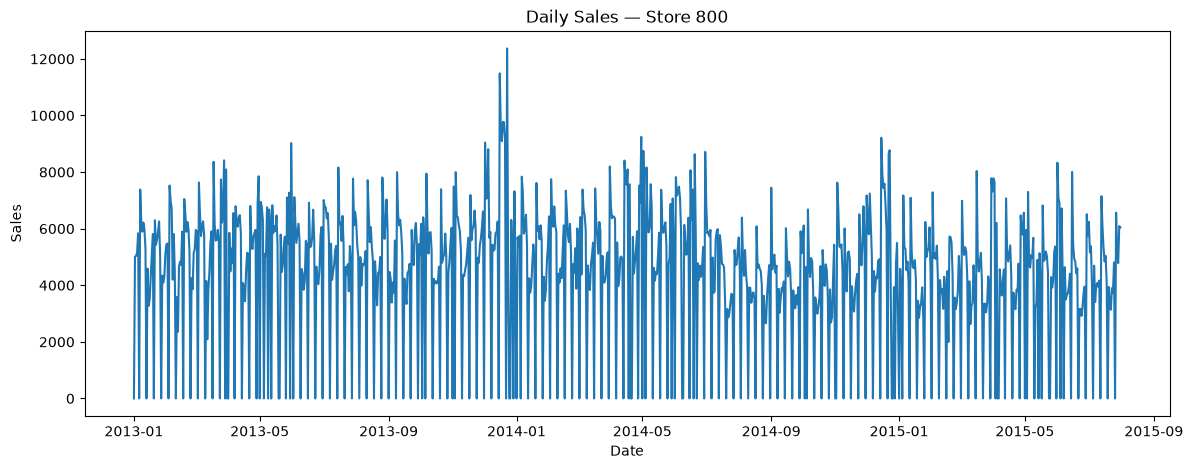

In [17]:
# Plot Store 800's daily sales over time
plt.figure(figsize=(14, 5))

plt.plot(sales.index, sales.values)

plt.title("Daily Sales — Store 800")
plt.xlabel("Date")
plt.ylabel("Sales")
plt.show()

In [18]:
# Reserve the final 42 days for testing
horizon = 42

train = sales.iloc[:-horizon]
test = sales.iloc[-horizon:]

print("Training observations:", len(train))
print("Testing observations:", len(test))
print("Test start date:", test.index.min())
print("Test end date:", test.index.max())

Training observations: 900
Testing observations: 42
Test start date: 2015-06-20 00:00:00
Test end date: 2015-07-31 00:00:00


## Decompose/ Training Data

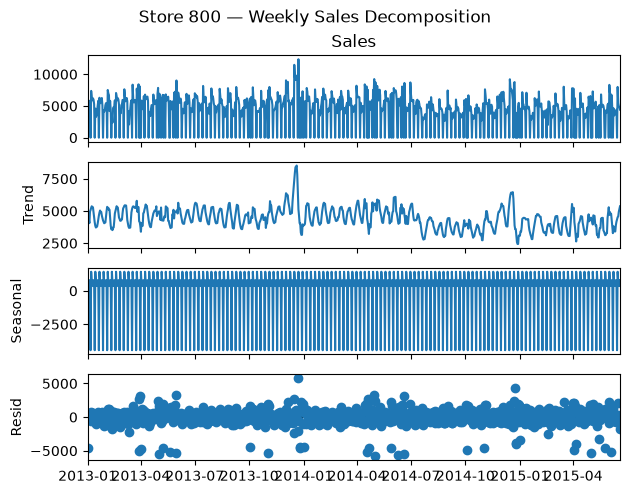

In [18]:
from statsmodels.tsa.seasonal import seasonal_decompose

decomposition = seasonal_decompose(
    train,
    model="additive",
    period=7,
    extrapolate_trend="freq"
)

decomposition.plot()
plt.suptitle("Store 800 — Weekly Sales Decomposition", y=1.02)
plt.show()

## Comparing Average Sales

In [36]:
# Calculate average sales and variation in daily sales each week
weekly_stats = pd.DataFrame({
    "Average_Sales": train.resample("W").mean(),
    "Sales_Variation": train.resample("W").std()
})

# Display the first five weeks
print(weekly_stats.head())

            Average_Sales  Sales_Variation
Date                                      
2013-01-06    3504.833333      2731.647592
2013-01-13    5291.714286      2415.179546
2013-01-20    3789.428571      1886.793740
2013-01-27    4929.714286      2219.087629
2013-02-03    4112.000000      1899.596097


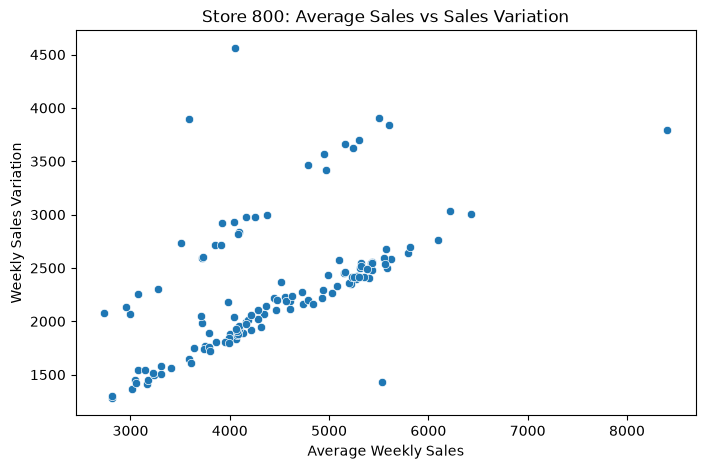

Correlation: 0.5694962946978346


In [37]:
# Plot average sales against weekly sales variation
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=weekly_stats,
    x="Average_Sales",
    y="Sales_Variation"
)

plt.title("Store 800: Average Sales vs Sales Variation")
plt.xlabel("Average Weekly Sales")
plt.ylabel("Weekly Sales Variation")
plt.show()

# Calculate the correlation
print(
    "Correlation:",
    weekly_stats["Average_Sales"].corr(
        weekly_stats["Sales_Variation"]
    )
)

In [43]:
print("Zero-sales days:", (train == 0).sum())
print("Negative-sales days:", (train < 0).sum())
print("All sales positive:", (train > 0).all())

Zero-sales days: 157
Negative-sales days: 0
All sales positive: False


## Forecasting Techniques

In [38]:
# Naive forecast: use the last training day's sales for all 42 days

horizon = len(test)

naive_forecast = pd.Series(
    np.repeat(train.iloc[-1], horizon),
    index=test.index
)

# Display the first five predicted values
print(naive_forecast.head())

# Display the last training sales value
print("Last observed training sales:", train.iloc[-1])

Date
2015-06-20    4424
2015-06-21    4424
2015-06-22    4424
2015-06-23    4424
2015-06-24    4424
Freq: D, dtype: int64
Last observed training sales: 4424


In [39]:
# Seasonal naive forecast: repeat the last 7 days of training sales
seasonal_forecast = pd.Series(
    np.resize(train.iloc[-7:].to_numpy(), len(test)),
    index=test.index
)

# Display the first 14 forecast values
print(seasonal_forecast.head(14))

Date
2015-06-20    4407
2015-06-21       0
2015-06-22    8003
2015-06-23    5457
2015-06-24    4940
2015-06-25    4840
2015-06-26    4424
2015-06-27    4407
2015-06-28       0
2015-06-29    8003
2015-06-30    5457
2015-07-01    4940
2015-07-02    4840
2015-07-03    4424
Freq: D, dtype: int64


In [40]:
# Calculate the average sales from the last 7 training days
last_week_average = train.iloc[-7:].mean()

# Use that average for all 42 forecast days
moving_average_forecast = pd.Series(
    np.repeat(last_week_average, len(test)),
    index=test.index
)

# Display the average and first 5 predictions
print("Last 7-day average:", last_week_average)
print(moving_average_forecast.head())

Last 7-day average: 4581.571428571428
Date
2015-06-20    4581.571429
2015-06-21    4581.571429
2015-06-22    4581.571429
2015-06-23    4581.571429
2015-06-24    4581.571429
Freq: D, dtype: float64


In [41]:
# Calculate the average daily change across the training period
average_change = (
    (train.iloc[-1] - train.iloc[0]) /
    (len(train) - 1)
)

# Forecast the next 42 days by extending that change
drift_forecast = pd.Series(
    train.iloc[-1] + average_change * np.arange(1, len(test) + 1),
    index=test.index
)

# Display the results
print("Average daily change:", average_change)
print(drift_forecast.head())

Average daily change: 4.921023359288098
Date
2015-06-20    4428.921023
2015-06-21    4433.842047
2015-06-22    4438.763070
2015-06-23    4443.684093
2015-06-24    4448.605117
Freq: D, dtype: float64


## Combining the full forecast

In [45]:
forecasts = {
    "Naive": naive_forecast,
    "Seasonal Naive": seasonal_forecast,
    "Moving Average": moving_average_forecast,
    "Drift": drift_forecast
}

print("Forecasts created:", list(forecasts.keys()))

Forecasts created: ['Naive', 'Seasonal Naive', 'Moving Average', 'Drift']


In [47]:
results = []

for name, forecast in forecasts.items():
    mae = mean_absolute_error(test, forecast)
    rmse = np.sqrt(mean_squared_error(test, forecast))

    results.append({
        "Baseline": name,
        "MAE": mae,
        "RMSE": rmse
    })

results_df = pd.DataFrame(results).sort_values("MAE")

print(results_df.to_string(index=False))

      Baseline         MAE        RMSE
Seasonal Naive 1004.833333 1479.892845
         Naive 1449.166667 1976.130978
         Drift 1450.924175 1993.408225
Moving Average 1471.676871 2019.246575


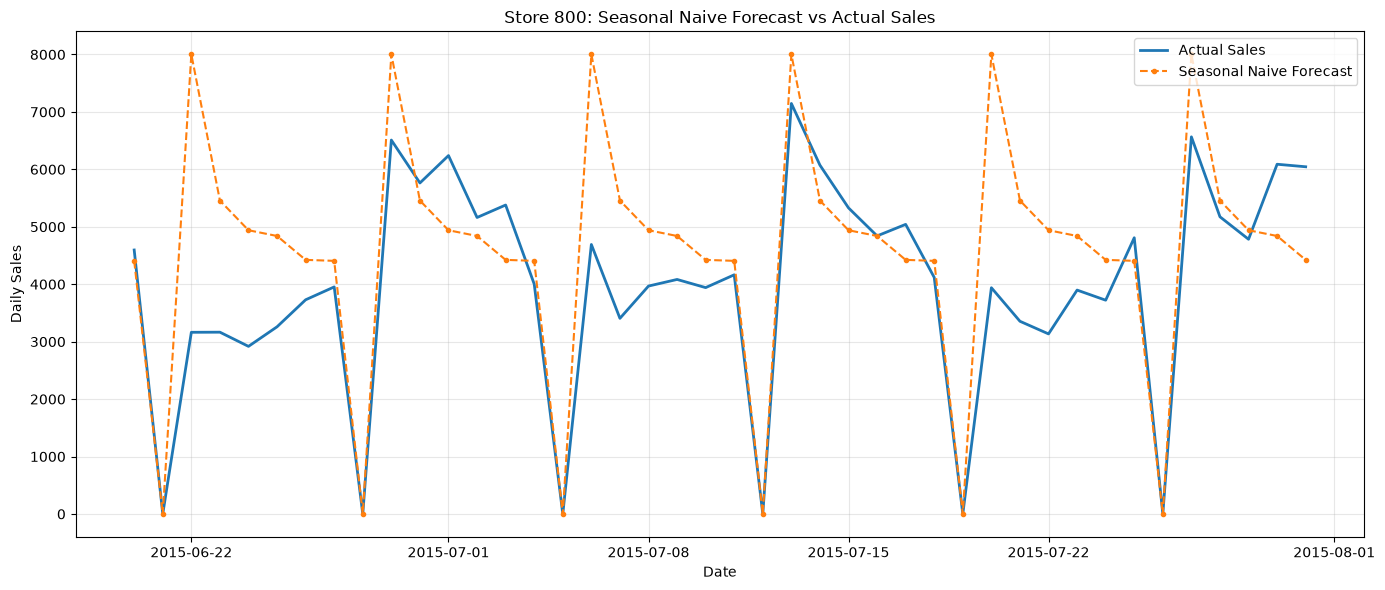

In [14]:
plt.figure(figsize=(14, 6))

plt.plot(
    chart_test.index, chart_test.values,
    label="Actual Sales", linewidth=2
)

plt.plot(
    chart_forecast.index, chart_forecast.values,
    label="Seasonal Naive Forecast",
    linestyle="--", marker="o", markersize=3
)

plt.title("Store 800: Seasonal Naive Forecast vs Actual Sales")
plt.xlabel("Date")
plt.ylabel("Daily Sales")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## Actual Sales against Full Forecast

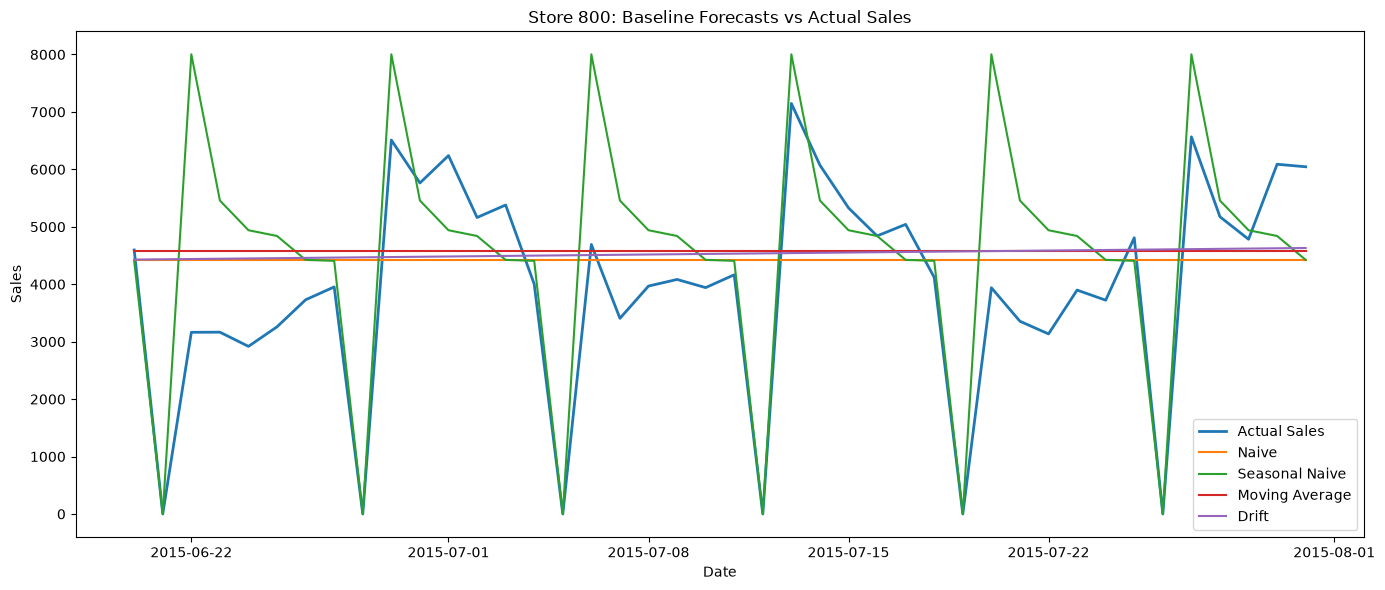

In [49]:
# Plot actual sales against all four baseline forecasts

plt.figure(figsize=(14, 6))

plt.plot(test.index, test.values,
         label="Actual Sales", linewidth=2)

for name, forecast in forecasts.items():
    plt.plot(test.index, forecast.values, label=name)

plt.title("Store 800: Baseline Forecasts vs Actual Sales")
plt.xlabel("Date")
plt.ylabel("Sales")
plt.legend()
plt.tight_layout()
plt.show()

## Key Findings: Time-Series Decomposition and Baseline Forecasting

### 1. Decomposition Findings

- **Strong weekly seasonality:** Store 800's daily sales exhibit a recurring seven-day pattern. Sunday sales are zero because the store is closed, making the day of the week an important feature of its observed sales behaviour.

- **Changing underlying trend:** The trend component varies over the study period, indicating that sales levels are not entirely constant over time. A forecasting model based only on a fixed average may therefore struggle to capture changes in the underlying sales level.

- **Irregular fluctuations remain:** The residual component contains variations not explained by the estimated trend and weekly seasonal pattern. These fluctuations indicate that decomposition alone does not fully explain daily sales behaviour.

- **Implication for forecasting:** The combination of weekly seasonality, a changing trend and unexplained fluctuations supports comparing seasonal methods with more advanced time-series models. However, the decomposition is descriptive and does not establish the cause of individual sales changes.

### 2. Baseline Forecasting Findings

- **Seasonal Naive was the strongest baseline:** Evaluated on the final 42 days, the Seasonal Naive method achieved an MAE of **1,004.83** and an RMSE of **1,479.89**, outperforming the ordinary Naive, Drift and Moving Average methods on both metrics.

- **Weekly repetition improved forecast accuracy:** Seasonal Naive reduced MAE by approximately **30.7%** and RMSE by approximately **25.1%** compared with the ordinary Naive method. This supports the usefulness of repeating the previous week's sales pattern for this particular forecast period.

- **The choice of baseline matters:** The Moving Average and Drift methods did not outperform Seasonal Naive on the selected holdout period. This suggests that preserving the weekly pattern was more useful here than relying solely on a smoothed average or a linear extrapolation of the training-period change.

- **The benchmark is promising, but not conclusive:** The results come from one 42-day test period. Performance may differ across other forecast origins or periods with different trading conditions. Rolling-origin backtesting is therefore needed before deciding whether Seasonal Naive is consistently reliable.

### 3. Overall Conclusion and Next Steps

The decomposition identifies weekly seasonality alongside a changing trend and unexplained daily fluctuations. Consistent with this pattern, Seasonal Naive provides the best of the four tested baselines for Store 800. It should serve as the benchmark for subsequent model development.

The next stage should assess stationarity on the training series, investigate whether differencing is appropriate, and use ACF/PACF analysis to guide model identification. Any advanced model should be evaluated against Seasonal Naive using the same forecast horizon and test observations, followed by residual diagnostics and rolling-origin backtesting.